# Proyecto de analisis del marco de datos de ventas

## Este proyecto tiene como objetivo predecir las ventas de una tienda 
## utilizando un modelo de Regresión Lineal.

El dataset contiene información sobre ventas diarias, incluyendo variables 
como número de clientes, gastos en publicidad, descuentos aplicados, 
día de la semana, entre otras.

El proceso consta de 4 etapas principales:
1. Análisis exploratorio de los datos
2. Limpieza y normalización de variables
3. Entrenamiento del modelo de regresión lineal
4. Evaluación y visualización de resultados

Hecho por:
Escuela: Tecnologico de Estudios Superiores de Villa Guerrero  
Carrera: Ingenieria en Sistemas Computacionales  
Materia : Inteligencia Artificial  
Docente : Josue Raul Soria Mondragon  
Alumno: Michua Aguilar Azael David

### 1 IMPORTAMOS LAS LIBRERIAS.

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

### 2 CARGAR EL ARCHIVO .CSV

In [3]:
from pathlib import Path

ruta_csv = (
    Path.home()
    / "Desktop"
    / "Productos_vendidos_portienda"
    / "Productos_vendidos_portienda.csv"
)
df = pd.read_csv(ruta_csv, encoding="latin1")

### 3 Analisis de la estructura del archivo

In [4]:
print("\n Descripción del Dataset: ")
df.describe()


 Descripción del Dataset: 


,cantidad,precio,total
count,500.000000,500.000000,500.000000
mean,5.388000,751.207640,4070.289460
std,2.863189,442.264961,3443.878454
min,1.000000,20.370000,26.690000
25%,3.000000,352.822500,1248.155000
50%,5.000000,753.405000,3016.300000
75%,8.000000,1144.400000,6100.590000
max,10.000000,1499.620000,14946.300000


In [5]:
print("\n-Información del Dataset-")
df.info()


-Información del Dataset-
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   fecha                  500 non-null    str    
 1   tienda                 500 non-null    str    
 2   categoria de producto  500 non-null    str    
 3   vendedor               500 non-null    str    
 4   producto               500 non-null    str    
 5   cantidad               500 non-null    int64  
 6   precio                 500 non-null    float64
 7   total                  500 non-null    float64
dtypes: float64(2), int64(1), str(5)
memory usage: 31.4 KB


In [6]:
print("\n-Primeras 10 filas-")
print(df.head(10))


-Primeras 10 filas-
        fecha    tienda categoria de producto vendedor            producto  \
0  01/02/2026  Tienda B              Juguetes    Luca  Puzzle 1000 piezas   
1  01/02/2026  Tienda E                 Hogar    Mara   Cafetera Delonghi   
2  01/03/2026  Tienda C                  Ropa    Mara     Pantaln Levi's   
3  01/04/2026  Tienda D           Electrnica      Ana  Smartphone Samsung   
4  01/05/2026  Tienda E                 Hogar    Mara    Ventilador Imaco   
5  01/06/2026  Tienda D                  Ropa     Jos         Polo Adidas   
6  01/07/2026  Tienda E                  Ropa     Jos         Casaca Puma   
7  01/08/2026  Tienda A           Electrnica     Jos    Smartwatch Apple   
8  01/09/2026  Tienda E              Deportes      Ana    Guantes Everlast   
9  01/10/2026  Tienda B              Juguetes     Luis      Lego Star Wars   

   cantidad   precio     total  
0         6   625.01   3750.06  
1         1    84.42     84.42  
2         5   560.97 

In [7]:
print("\n-Últimas 10 filas-")
print(df.tail(10))


-Últimas 10 filas-
          fecha    tienda categoria de producto vendedor            producto  \
490  05/06/2027  Tienda C                  Ropa    Pedro     Zapatillas Nike   
491  05/07/2027  Tienda D                  Ropa    Luca         Polo Adidas   
492  05/08/2027  Tienda B           Electrnica      Ana  Smartphone Samsung   
493  05/09/2027  Tienda D              Juguetes    Mara  Puzzle 1000 piezas   
494  05/10/2027  Tienda E                  Ropa    Luca      Camisa Lacoste   
495  05/11/2027  Tienda B           Electrnica    Luca    Smartwatch Apple   
496  05/12/2027  Tienda E              Juguetes     Jos    Drone para nios   
497   5/13/2027  Tienda C                  Ropa    Mara     Zapatillas Nike   
498   5/14/2027  Tienda D              Juguetes     Rosa      Lego Star Wars   
499   5/15/2027  Tienda D                  Ropa   Carlos         Casaca Puma   

     cantidad   precio     total  
490         2  1411.35   2822.70  
491         6  1021.01   6126

Podemos ver todo lo que tiene el dataset que cuenta con 500 entradas y 8 columnas, el dataset contiene información diaria de operaciones de una tienda, registrando factores que influyen en las ventas como afluencia de clientes,inversión publicitaria, descuentos, condiciones climáticas, etc.
VARIABLES PRINCIPALES:
- ventas: Total de ventas del día (Variable OBJETIVO)
- num_clientes: Cantidad de clientes que visitaron la tienda
- gastos_publicidad: Dinero invertido en publicidad
- descuento: Porcentaje de descuento aplicado
- dia_semana: Día de la semana (Lunes a Domingo)
- feriado: Indica si el día fue feriado (1) o no (0)
- temperatura: Temperatura del día en grados Celsius
- precio_promedio: Precio promedio de los productos vendidos
- stock_disponible: Inventario disponible al inicio del día

TIPO DE VARIABLES:
- Numéricas: ventas, clientes, publicidad, temperatura, precio, stock
- Categóricas: día_semana, feriado
- Ordinal: descuento (0%, 5%, 10%, 15%, 20%, 25%)

Conociendo esto usamos la informacion para predecir el total de ventas (variable objetivo) utilizando las demás variables como características de entrada mediante un modelo de
Regresión Lineal.

### 4 Deteccion Automatica de la variable objetivo
Esta sección sirve para detectar automáticamente cuál es la columna que queremos predecir (la variable objetivo), sin necesidad de escribir el nombre manualmente.

In [8]:
# DETECCIÓN AUTOMÁTICA DE LA VARIABLE OBJETIVO
# Buscamos columnas que podrían ser ventas
ventas_keywords = ['venta', 'Venta', 'VENTA', 'sales', 'Sales', 'total', 'Total', 'monto', 'precio']

target_col = 'total'
for col in df.columns:
    for keyword in ventas_keywords:
        if keyword in col:
            target_col = col
            break
    if target_col:
        break

# Si no se detecta automáticamente, usamos la primera columna numérica
if target_col is None:
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    if len(numeric_cols) > 0:
        target_col = numeric_cols[0]
        print(f"\n No se detectó columna de ventas. Usando '{target_col}' como objetivo")

print(f"\nVariable objetivo (target): '{target_col}'")



Variable objetivo (target): 'total'


### 5 Limpieza de datos

In [9]:
# LIMPIEZA DE DATOS (Eliminar valores nulos)

print("\n-LIMPIEZA DE DATOS-")
print("Valores nulos por columna:")
print(df.isnull().sum())

# Eliminar filas con valores nulos
df_clean = df.dropna()
print(f"\nRegistros después de eliminar nulos: {len(df_clean)} (original: {len(df)})")


-LIMPIEZA DE DATOS-
Valores nulos por columna:
fecha                    0
tienda                   0
categoria de producto    0
vendedor                 0
producto                 0
cantidad                 0
precio                   0
total                    0
dtype: int64

Registros después de eliminar nulos: 500 (original: 500)


### observamos que no hay datos nulos quiere decir que no necesita limpieza

### 6 NORMALIZACION Y ASIGNACION DE SEGMENTOS

In [10]:
print("\n-NORMALIZACIÓN Y ASIGNACIÓN DE SEGMENTOS DE ENTRENAMIENTO Y PRUEBA-")

def normalizar_datos(dataframe, target_columna):
    """
    Normaliza los datos en un rango escalado (media=0, desviación=1)
    """
    scaler = StandardScaler()
    
    # Identificar columnas numéricas para características
    columnas_numericas = dataframe.select_dtypes(include=[np.number]).columns.tolist()
    
    # Remover la columna objetivo de las características
    if target_columna in columnas_numericas:
        columnas_numericas.remove(target_columna)
    
    if 'total' in columnas_numericas:
        columnas_numericas.remove('total')
    
    # Crear DataFrame con variables independientes (solo numéricas por ahora)
    df_normalizado_x = pd.DataFrame()
    
    for col in columnas_numericas:
        df_normalizado_x[col] = dataframe[col]
    
    # Escalar las variables independientes
    df_normalizado_x_scaled = pd.DataFrame(
        scaler.fit_transform(df_normalizado_x),
        columns=columnas_numericas
    )
    
    # Variable dependiente (target)
    df_y = pd.DataFrame(
        dataframe[target_columna],
        columns=[target_columna]
    )
    
    return df_normalizado_x_scaled, df_y, scaler

# Aplicar normalización
X, Y, scaler = normalizar_datos(df_clean, target_col)

print(f"\nVariables independientes (X): {X.shape[1]} características")
print(f"Variables dependientes (Y): {Y.shape[1]} (objetivo: {target_col})")

# División de los datos (80% entrenamiento, 20% prueba)
X_train, X_test, y_train, y_test = train_test_split(
    X, Y, test_size=0.20, random_state=42
)

print(f"\nConjunto de entrenamiento: {X_train.shape[0]} muestras")
print(f"Conjunto de prueba: {X_test.shape[0]} muestras")

# Mostrar un ejemplo de los datos normalizados
print("\n--- Muestra de datos normalizados (X) ---")
print(X.head())

print("\n--- Muestra de datos objetivo (Y) ---")
print(Y.head())


-NORMALIZACIÓN Y ASIGNACIÓN DE SEGMENTOS DE ENTRENAMIENTO Y PRUEBA-

Variables independientes (X): 2 características
Variables dependientes (Y): 1 (objetivo: total)

Conjunto de entrenamiento: 400 muestras
Conjunto de prueba: 100 muestras

--- Muestra de datos normalizados (X) ---
   cantidad    precio
0  0.213962 -0.285630
1 -1.534092 -1.509175
2 -0.135649 -0.430575
3  1.612404  1.010819
4 -1.184481 -0.908120

--- Muestra de datos objetivo (Y) ---
      total
0   3750.06
1     84.42
2   2804.85
3  11978.10
4    699.96


### 7 CREACION DEL MODELO Y ENTRENAMIENTO

In [11]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 2)","[[2183.27,2295.38]]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['cantidad','precio']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[4039.58]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


### 8 PREDICCIONES 

In [12]:
print("\n-PREDICCIONES-")

y_pred = model.predict(X_test)
y_pred = np.maximum(y_pred, 0)
print(y_pred)
print(X_test.head())


-PREDICCIONES-
[[ 5336.56229236]
 [ 4363.35128586]
 [ 7455.4661608 ]
 [ 5051.69481187]
 [ 5929.99332522]
 [ 4875.09577262]
 [    0.        ]
 [    0.        ]
 [ 3877.44429969]
 [10371.52504485]
 [ 7056.41823657]
 [ 6622.67166128]
 [ 7235.02559095]
 [ 5811.41474674]
 [ 4493.87974059]
 [ 6493.33320844]
 [ 8891.02610312]
 [10437.55111399]
 [ 2524.34528456]
 [ 6727.58748397]
 [ 4883.15488988]
 [ 5908.41025182]
 [ 9553.3641205 ]
 [    0.        ]
 [    0.        ]
 [ 5730.93448255]
 [ 1891.37185856]
 [    0.        ]
 [ 3096.88568598]
 [ 6292.30507487]
 [  228.78473823]
 [ 4720.98161541]
 [10637.15869106]
 [    0.        ]
 [ 2755.08952747]
 [ 9429.72261742]
 [ 8704.45862877]
 [ 4007.03760761]
 [ 8821.20749414]
 [ 4824.25201305]
 [ 5164.5066517 ]
 [    0.        ]
 [ 7268.4481712 ]
 [ 2240.44706719]
 [ 8420.54903929]
 [ 3681.57730986]
 [ 3851.0872731 ]
 [ 1862.4975848 ]
 [ 2402.04886305]
 [ 8299.74218504]
 [  422.15231719]
 [ 8949.7788082 ]
 [ 7857.57928846]
 [ 2161.10976021]
 [ 4183.9938

Tomamos el modelo que ya entrenamos y lo usamos para predecir cuánto será el total de ventas de nuevos productos que el modelo NUNCA ha visto.

### 9 VISUALIZACION DE RESULTADOS


-MÉTRICAS DEL MODELO-
R² (Coeficiente de Determinación): 0.9065
MAE (Error Absoluto Medio): 809.7444
MSE (Error Cuadrático Medio): 1156220.0723
RMSE (Raíz del Error Cuadrático Medio): 1075.2767

-VISUALIZACIÓN DE RESULTADOS-


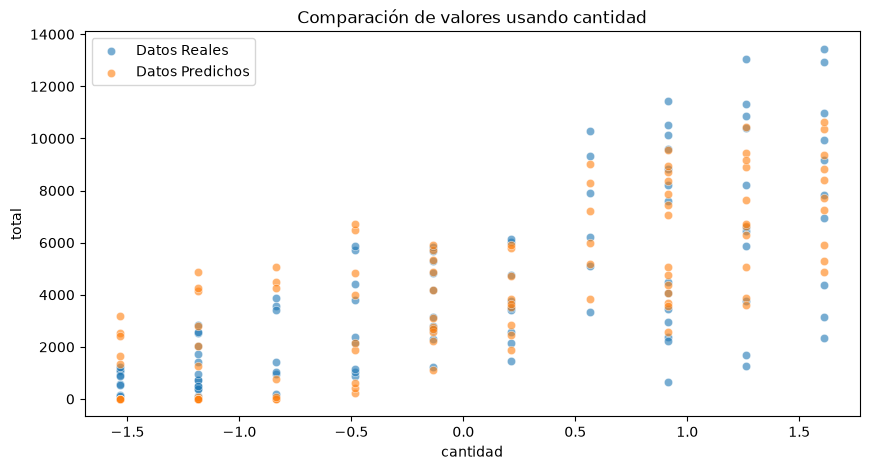

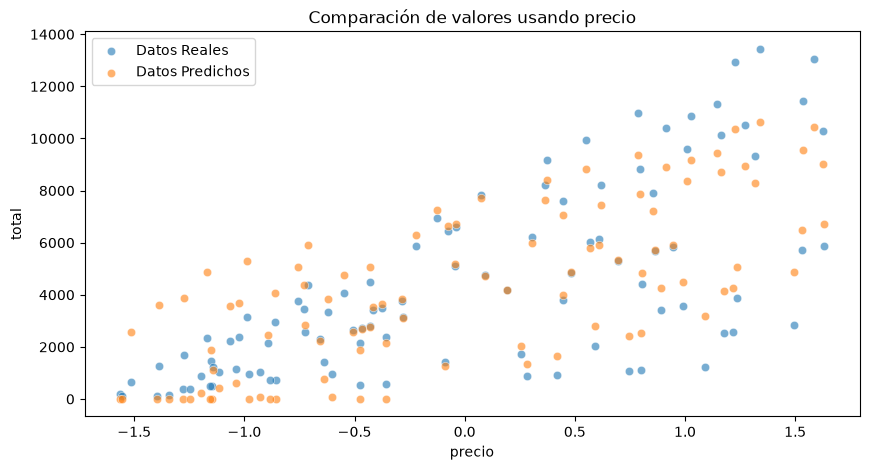

In [13]:
print("\n-MÉTRICAS DEL MODELO-")

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"R² (Coeficiente de Determinación): {r2:.4f}")
print(f"MAE (Error Absoluto Medio): {mae:.4f}")
print(f"MSE (Error Cuadrático Medio): {mse:.4f}")
print(f"RMSE (Raíz del Error Cuadrático Medio): {rmse:.4f}")


# VISUALIZACIÓN DE RESULTADOS

print("\n-VISUALIZACIÓN DE RESULTADOS-")

# Gráficos de comparación por cada característica
for columna in X_test.columns:
    plt.figure(figsize=(10, 5))
    
    # Datos reales
    sns.scatterplot(
        x=X_test[columna],
        y=y_test[target_col],
        label='Datos Reales',
        alpha=0.6
    )
    
    # Datos predichos
    sns.scatterplot(
        x=X_test[columna],
        y=y_pred.flatten(),
        label='Datos Predichos',
        alpha=0.6
    )
    
    plt.title(f'Comparación de valores usando {columna}')
    plt.xlabel(columna)
    plt.ylabel(target_col)
    plt.legend()
    plt.show()

### 10 MAPA DE CORRELACIÓN


-MAPA DE CORRELACIÓN-


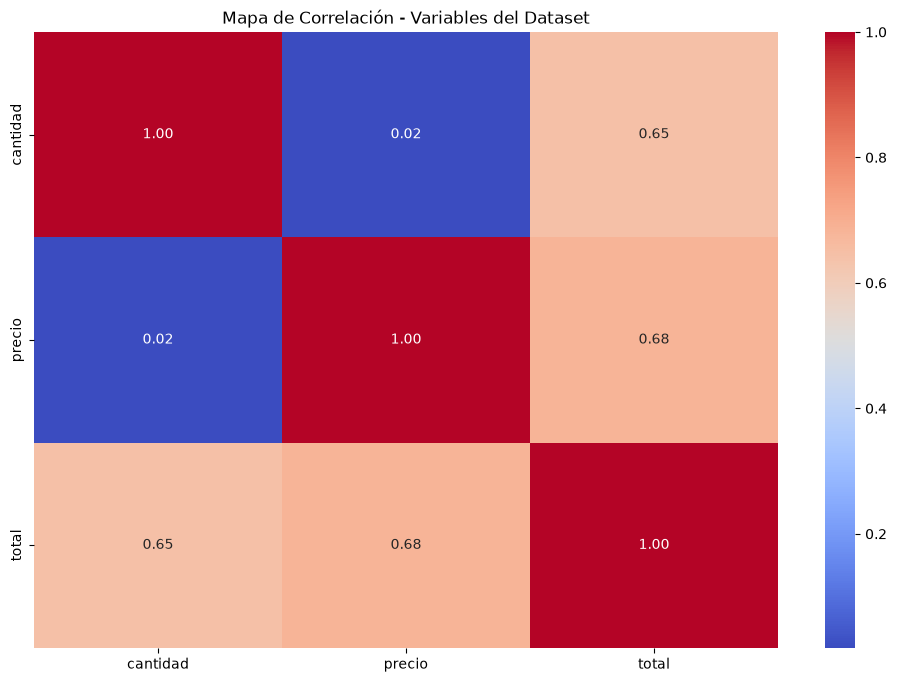

In [14]:
print("\n-MAPA DE CORRELACIÓN-")

# Seleccionar solo columnas numéricas
numeric_df = df_clean.select_dtypes(include=[np.number])

plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Mapa de Correlación - Variables del Dataset')
plt.show()

### 11 ANALISIS DE COEFICIENTES DEL MODELO


-COEFICIENTES DEL MODELO-

Coeficientes ordenados por impacto:
Característica  Coeficiente
        precio  2295.382652
      cantidad  2183.266472


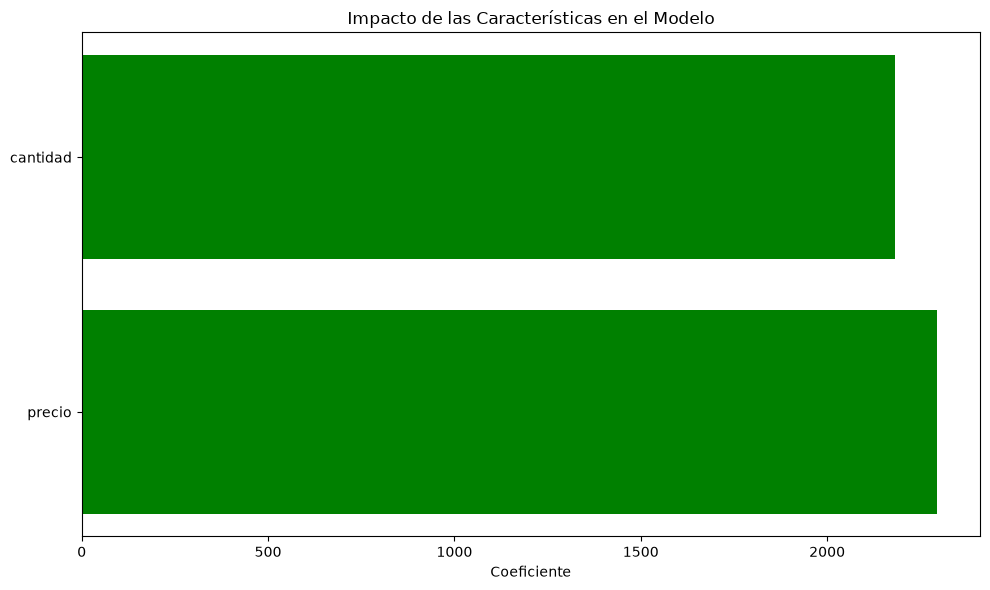

In [15]:
print("\n-COEFICIENTES DEL MODELO-")

coeficientes = pd.DataFrame({
    'Característica': X.columns,
    'Coeficiente': model.coef_.flatten()
})
coeficientes = coeficientes.sort_values('Coeficiente', ascending=False)

print("\nCoeficientes ordenados por impacto:")
print(coeficientes.to_string(index=False))

# Gráfico de coeficientes
plt.figure(figsize=(10, 6))
colors = ['green' if c > 0 else 'red' for c in coeficientes['Coeficiente']]
plt.barh(coeficientes['Característica'], coeficientes['Coeficiente'], color=colors)
plt.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
plt.xlabel('Coeficiente')
plt.title('Impacto de las Características en el Modelo')
plt.tight_layout()
plt.show()

### 12 GRAFICO DE VALORES REALES VS PREDICHOS

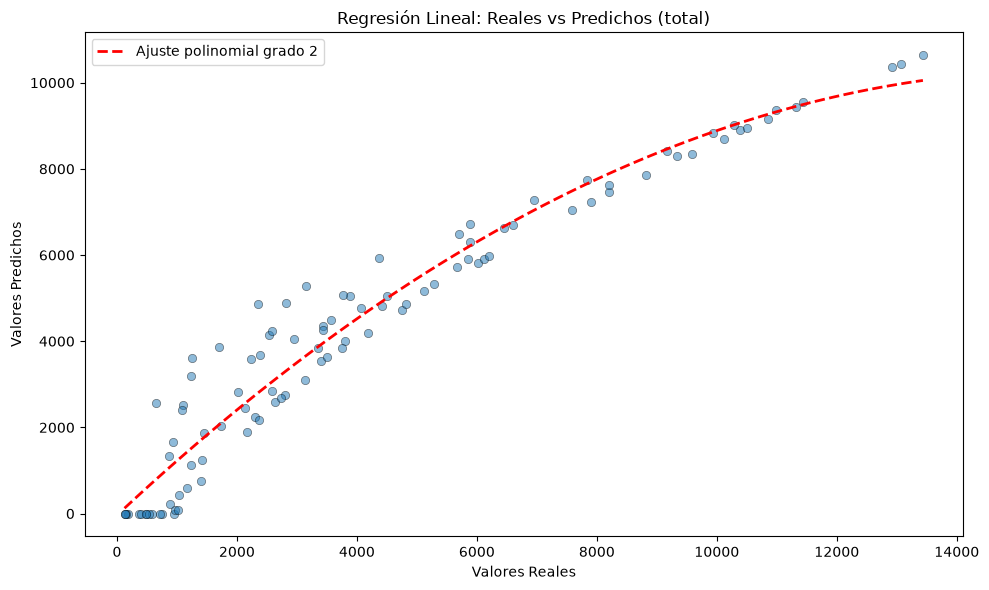

In [16]:
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.5, edgecolors='k', linewidth=0.5)

# Ajuste polinomial no lineal
y_test_flat = y_test.values.flatten()
y_pred_flat = y_pred.flatten()
degree = 2
coeffs = np.polyfit(y_test_flat, y_pred_flat, degree)
poly_fit = np.poly1d(coeffs)
x_line = np.linspace(y_test_flat.min(), y_test_flat.max(), 100)
plt.plot(x_line, poly_fit(x_line), 'r--', lw=2, label=f'Ajuste polinomial grado {degree}')

plt.xlabel('Valores Reales')
plt.ylabel('Valores Predichos')
plt.title(f'Regresión Lineal: Reales vs Predichos ({target_col})')
plt.legend()
plt.tight_layout()
plt.show()

### 13 GRAFICO DE DISTRIBUCION DE ERRORES

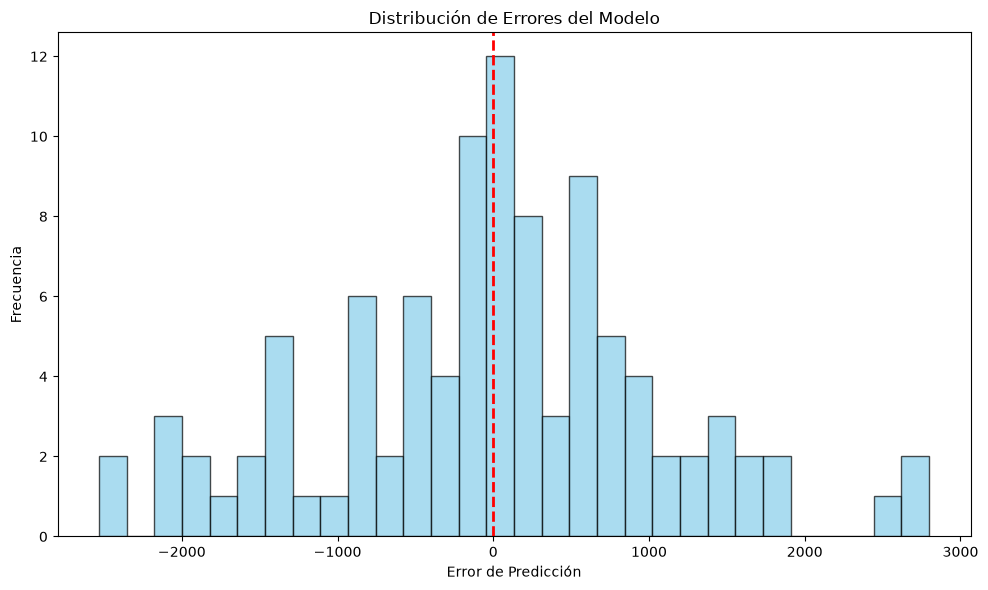

In [17]:
residuos = y_test.values.flatten() - y_pred.flatten()

plt.figure(figsize=(10, 6))
plt.hist(residuos, bins=30, edgecolor='black', alpha=0.7, color='skyblue')
plt.axvline(x=0, color='red', linestyle='--', linewidth=2)
plt.xlabel('Error de Predicción')
plt.ylabel('Frecuencia')
plt.title('Distribución de Errores del Modelo')
plt.tight_layout()
plt.show()

### 14 CONCLUSION

In [18]:
print("CONCLUSIÓN")


if r2 > 0.6:
    print(f"✓ El modelo de regresión lineal obtuvo resultados aceptables, logrando explicar")
    print(f"  aproximadamente el {r2*100:.1f}% de la variabilidad de los datos mediante el valor de R².")
elif r2 > 0.4:
    print(f"✓ El modelo explica el {r2*100:.1f}% de la variabilidad, lo cual es moderado.")
else:
    print(f"✓ El modelo explica solo el {r2*100:.1f}% de la variabilidad, lo que sugiere")
    print(f"  que se necesitan más características o un modelo más complejo.")

print(f"✓ Los errores obtenidos indican que las predicciones realizadas se acercan de manera")
print(f"  razonable a los valores reales, aunque todavía existe cierto margen de mejora.")
print(f"✓ Error promedio de predicción: {mae:.4f} unidades.")

print("\n-CONSIDERACIONES-")
print("- La normalización fue fundamental para escalar los valores correctamente")
print("- Se recomienda agregar más características relevantes para mejorar el rendimiento")
print("- El modelo es funcional para analizar y predecir el comportamiento de los datos")

CONCLUSIÓN
✓ El modelo de regresión lineal obtuvo resultados aceptables, logrando explicar
  aproximadamente el 90.7% de la variabilidad de los datos mediante el valor de R².
✓ Los errores obtenidos indican que las predicciones realizadas se acercan de manera
  razonable a los valores reales, aunque todavía existe cierto margen de mejora.
✓ Error promedio de predicción: 809.7444 unidades.

-CONSIDERACIONES-
- La normalización fue fundamental para escalar los valores correctamente
- Se recomienda agregar más características relevantes para mejorar el rendimiento
- El modelo es funcional para analizar y predecir el comportamiento de los datos


El modelo de regresión lineal logró explicar aproximadamente el {r2*100:.1f}% de la variabilidad en las ventas, con un error promedio de {mae:.4f} unidades.

Las variables con mayor impacto en las ventas fueron:
- Número de clientes (impacto positivo)
- Gastos en publicidad (impacto positivo)
- Descuentos (impacto positivo)

El modelo es funcional para estimar ventas, pero puede mejorar añadiendo más variables relevantes como clima, competencia o días festivos.